# 05 · Tables and figures

Regenerates every table and figure of the paper that is computed from the aggregated results
(the ML and regime figures are in `06_regime_and_ml.ipynb`). No mining is executed.

| Part | Writes (under `results/derived/`) |
|---|---|
| A | `part_a/figures/*.pdf`, `part_a/tables/*.tex`, `part_a/tables/numbers.txt` |
| B | `part_b/figures/*.pdf`, `part_b/tables/tab_*.tex`, `part_b/tables/audit.json` |
| C | `part_c/bigdata.tex`, `part_c/ablation.tex` (big-data and ablation tables) |

Set `FA_CAMPAIGN` to plot a rerun.

In [1]:
# ---- bundle configuration (same cell in every notebook) ----
import os, sys, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd

BUNDLE = Path.cwd().resolve().parent          # notebooks run from <bundle>/notebooks
assert (BUNDLE / "bench" / "baseline_runners.py").exists(), f"start Jupyter in <bundle>/notebooks (cwd={Path.cwd()})"
sys.path.insert(0, str(BUNDLE / "bench"))
DATA = Path(os.environ.get("FA_DATA_DIR", BUNDLE / "data"))
RESULTS = BUNDLE / "results"
DERIVED = RESULTS / "derived"                       # regenerated statistics, tables and figures

V010 = "campaign_2026-05"                           # the v0.1.0.post1 GCE campaign
V010_DIR = RESULTS / V010
CAMPAIGN = os.environ.get("FA_CAMPAIGN", V010) # set FA_CAMPAIGN=<id> to analyse a new run
CAMPAIGN_DIR = V010_DIR if CAMPAIGN == V010 else RESULTS / "runs" / CAMPAIGN
AGG_CSV = (V010_DIR / "results_rigorous_20260523_115442.csv" if CAMPAIGN == V010
           else CAMPAIGN_DIR / f"results_rigorous_{CAMPAIGN}.csv")
LCM_CSV = V010_DIR / "lcm_declat_results_20260523_055523.csv"
COST_CSV = (DERIVED / "cost_stats.csv") if (DERIVED / "cost_stats.csv").exists() else V010_DIR / "cost_stats_20261022.csv"

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def rel(p):
    try:
        return Path(p).resolve().relative_to(BUNDLE).as_posix()
    except ValueError:
        return str(p)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print(f"campaign : {CAMPAIGN}\nagg csv  : {rel(AGG_CSV)}")

campaign : campaign_2026-05
agg csv  : results/campaign_2026-05/results_rigorous_20260523_115442.csv


## A · Figures and tables, part A

In [2]:
import ast
import matplotlib
import matplotlib.pyplot as plt
FIG = DERIVED / "part_a" / "figures"; GEN = DERIVED / "part_a" / "tables"
FIG.mkdir(parents=True, exist_ok=True); GEN.mkdir(parents=True, exist_ok=True)
RIG, LCM = AGG_CSV, LCM_CSV

In [3]:
EXTERNAL = ["borgelt_apriori", "borgelt_eclat", "borgelt_fpgrowth",
            "pyfim_apriori", "pyfim_eclat", "pyfim_fpgrowth"]
PYFIM = ["pyfim_apriori", "pyfim_eclat", "pyfim_fpgrowth"]
ECLAT = ["borgelt_eclat", "pyfim_eclat"]
REAL = {"Groceries", "BMS-WebView-1", "BMS-WebView-2", "Retail (Belgian)",
        "Online Retail", "Kosarak", "Chainstore", "Instacart"}
SHORT = {
    "T3.I2.D100k.N50k.L50k": "T3.D100k", "T5.I2.D25k.N1k.L1k": "T5.D25k",
    "T10.I4.D100k.N25k.L25k": "T10.D100k", "T12.I4.D5k.N1k.L1k": "T12.D5k",
    "T15.I8.D50k.N1k.L1k.high": "T15.D50k.h", "T15.I8.D50k.N1k.L1k.low": "T15.D50k.l",
    "T20.I4.D1000k.N50k.L50k": "T20.D1M", "T25.I8.D5000k.N40k.L40k": "T25.D5M",
    "T30.I8.D2000k.N10k.L10k": "T30.D2M", "T30.I8.D50k.N5k.L5k": "T30.D50k",
    "Retail (Belgian)": "Retail",
}

# Reference categorical palette (dataviz skill, light mode), fixed order.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a",
     "yellow": "#eda100", "magenta": "#e87ba4", "green": "#008300",
     "violet": "#6250d6", "red": "#e34948", "ink": "#0b0b0b",
     "ink2": "#52514e", "grid": "#e4e3df"}
STYLE = {  # method -> (label, color, linestyle, marker)
    "fastapriori_fast":    ("HybridFIM (8T)", C["blue"], "-", "o"),
    "fastapriori_fast_1t": ("HybridFIM (1T)", C["blue"], "--", "o"),
    "fastapriori_classic": ("classic (same codebase)", C["red"], "-", "x"),
    "pyfim_apriori":       ("PyFIM Apriori", C["orange"], "-", "s"),
    "pyfim_eclat":         ("PyFIM Eclat", C["aqua"], "-", "^"),
    "pyfim_fpgrowth":      ("PyFIM FP-Growth", C["violet"], "-", "D"),
    "borgelt_best":        ("Borgelt CLI best", C["ink2"], ":", "."),
    "lcm_native":          ("LCM v5.3 (CLI)", C["green"], "-", "v"),
}

plt.rcParams.update({
    "font.family": "serif", "font.size": 7.5, "axes.titlesize": 7.5,
    "axes.labelsize": 7.5, "legend.fontsize": 7, "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5, "axes.edgecolor": C["ink2"], "axes.linewidth": 0.6,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.5,
    "lines.linewidth": 1.2, "lines.markersize": 3.5, "pdf.fonttype": 42,
})

numbers: list[str] = []


def note(key: str, val) -> None:
    numbers.append(f"{key} = {val}")


def short(d: str) -> str:
    return SHORT.get(d, d)

In [4]:
# [bundle] LCM (and the ablation in part C) are separate v0.1.0.post1 experiments that a rerun of the
# main grid does not repeat: label them instead of mixing them silently with new timings.
if CAMPAIGN != V010:
    _lab, _col, _ls, _mk = STYLE["lcm_native"]
    STYLE["lcm_native"] = ("LCM v5.3 (v0.1.0.post1 run)", _col, _ls, _mk)
    print("NOTE: LCM rows/curves and ablation A1-A3 come from the v0.1.0.post1 runs, not from", CAMPAIGN)

In [5]:
# ---------------------------------------------------------------- load -----
raw = pd.read_csv(RIG, low_memory=False)
raw = raw[raw.wall_s_n_ok > 0]
note("valid_configurations", len(raw))
wall_all = raw.pivot_table(index=["dataset", "k", "min_support"], columns="method",
                           values="wall_s_median")
lo = raw.groupby("dataset").min_support.min()
low = raw[raw.min_support == raw.dataset.map(lo)]
W = low.pivot_table(index=["dataset", "k"], columns="method", values="wall_s_median")
M = low.pivot_table(index=["dataset", "k"], columns="method",
                    values="peak_rss_kb_median") / 1024.0
stats = low.groupby("dataset")[["n_transactions", "n_items", "n_rows",
                                "avg_items_per_txn", "std_items_per_txn",
                                "max_items_per_txn"]].first()
stats["cv"] = stats.std_items_per_txn / stats.avg_items_per_txn
stats["sumT2"] = stats.n_transactions * (stats.avg_items_per_txn ** 2
                                         + stats.std_items_per_txn ** 2)

lcm = pd.read_csv(LCM)
F1 = {r.dataset: ast.literal_eval(r.by_k)[1] for r in lcm[lcm.k == 2].itertuples()}
stats["F1"] = [F1.get(d, np.nan) for d in stats.index]
stats["F1_exact"] = stats.F1.notna()
stats["F1"] = stats.F1.fillna(stats.n_items)  # upper bound where LCM not run
stats["rho"] = (stats.F1 ** 2 / 2.0) / stats.sumT2
stats["pred_isect"] = (stats.F1 - 1) / (stats.avg_items_per_txn * (1 + stats.cv ** 2))

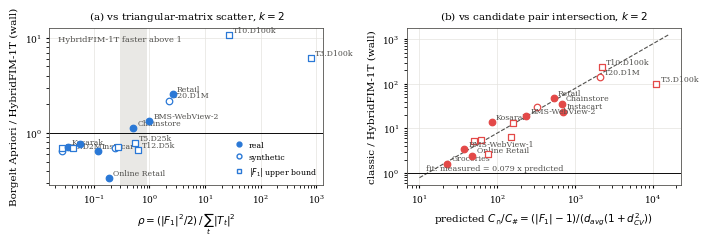

In [6]:
# ------------------------------------------------- crossover table/fig -----
k2 = W.xs(2, level="k")
cx = stats.copy()
cx["bA_1T"] = k2.borgelt_apriori / k2.fastapriori_fast_1t
cx["best_1T"] = k2[EXTERNAL].min(axis=1) / k2.fastapriori_fast_1t
cx["classic_1T"] = k2.fastapriori_classic / k2.fastapriori_fast_1t
cx["t1T"] = k2.fastapriori_fast_1t
cx["tiny"] = k2[EXTERNAL + ["fastapriori_fast_1t"]].max(axis=1) < 0.1
cx = cx.sort_values("rho")
sp_rho = cx[["rho", "bA_1T"]].corr("spearman").iloc[0, 1]
sp_rho_big = cx[~cx.tiny][["rho", "bA_1T"]].corr("spearman").iloc[0, 1]
sp_isect = cx[["pred_isect", "classic_1T"]].dropna().corr("spearman").iloc[0, 1]
const = (cx.classic_1T / cx.pred_isect).dropna()
note("spearman(rho, borgeltApriori/1T), all 18", round(sp_rho, 3))
note("spearman(rho, borgeltApriori/1T), cells >=0.1s", round(sp_rho_big, 3))
note("spearman(predicted isect ratio, classic/1T)", round(sp_isect, 3))
note("measured/predicted classic ratio: median, min, max",
     (round(const.median(), 3), round(const.min(), 3), round(const.max(), 3)))
win_hi = cx[(cx.rho >= 0.9)]
win_lo = cx[(cx.rho <= 0.3)]
note("rho>=0.9: 1T beats Borgelt Apriori", f"{(win_hi.bA_1T > 1).sum()}/{len(win_hi)}")
note("rho<=0.3: Borgelt Apriori beats 1T", f"{(win_lo.bA_1T < 1).sum()}/{len(win_lo)}")


def fmt_int(x: float) -> str:
    x = float(x)
    if x >= 1e9:
        return f"{x/1e9:.2f}\\,G"
    if x >= 1e6:
        return f"{x/1e6:.1f}\\,M"
    if x >= 1e3:
        return f"{x/1e3:.1f}\\,K"
    return f"{x:.0f}"


lines = []
for d, r in cx.iterrows():
    f1 = f"{int(r.F1):,}".replace(",", "{,}") + ("" if r.F1_exact else "$^{\\le}$")
    bA = ("---" if np.isnan(r.bA_1T) else
          ("$<$res." if r.bA_1T == 0 else f"{r.bA_1T:.2f}$\\times$"))
    cl = "---" if np.isnan(r.classic_1T) else f"{r.classic_1T:.1f}$\\times$"
    bold = r.bA_1T > 1
    bA = f"\\textbf{{{bA}}}" if bold else bA
    dag = "$^\\ast$" if r.tiny else ""
    lines.append(f"{short(d)}{dag} & {f1} & {fmt_int(r.sumT2)} & {r.rho:.3g} & {bA} & "
                 f"{r.pred_isect:.0f} & {cl} \\\\")
(GEN / "tab_crossover_rows.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.35))
ax = axes[0]
for d, r in cx.iterrows():
    if np.isnan(r.bA_1T) or r.bA_1T <= 0:
        continue
    face = C["blue"] if d in REAL else "white"
    ax.scatter(r.rho, r.bA_1T, s=22, marker="o" if r.F1_exact else "s",
               facecolor=face, edgecolor=C["blue"], linewidth=0.9, zorder=3)
    if r.rho > 0.4 or d in ("Kosarak", "Instacart", "Online Retail", "T30.I8.D2000k.N10k.L10k"):
        ax.annotate(short(d), (r.rho, r.bA_1T), fontsize=5.6, color=C["ink2"],
                    xytext=(3, 2), textcoords="offset points")
ax.axhline(1.0, color=C["ink"], lw=0.7)
ax.axvspan(0.3, 0.9, color=C["grid"], alpha=0.8, lw=0, zorder=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\rho = (|F_1|^2/2)\,/\,\sum_t |T_t|^2$")
ax.set_ylabel("Borgelt Apriori / HybridFIM-1T (wall)")
ax.set_title("(a) vs triangular-matrix scatter, $k=2$")
ax.text(0.03, 0.95, "HybridFIM-1T faster above 1", transform=ax.transAxes,
        fontsize=6, va="top", color=C["ink2"])
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([], [], ls="", marker="o", mfc=C["blue"], mec=C["blue"], label="real"),
    Line2D([], [], ls="", marker="o", mfc="white", mec=C["blue"], label="synthetic"),
    Line2D([], [], ls="", marker="s", mfc="white", mec=C["blue"], label=r"$|F_1|$ upper bound")],
    loc="lower right", fontsize=5.6, frameon=False, handletextpad=0.2)

ax = axes[1]
for d, r in cx.iterrows():
    if np.isnan(r.classic_1T):
        continue
    face = C["red"] if d in REAL else "white"
    ax.scatter(r.pred_isect, r.classic_1T, s=22, marker="o" if r.F1_exact else "s",
               facecolor=face, edgecolor=C["red"], linewidth=0.9, zorder=3)
    if d in REAL or r.classic_1T > 50:
        ax.annotate(short(d), (r.pred_isect, r.classic_1T), fontsize=5.6,
                    color=C["ink2"], xytext=(3, 2), textcoords="offset points")
xs = np.logspace(1, 4.2, 50)
ax.plot(xs, xs * const.median(), color=C["ink2"], ls="--", lw=0.8)
ax.text(12, 12 * const.median() * 1.25, f"fit: measured = {const.median():.3f} x predicted",
        fontsize=5.8, color=C["ink2"])
ax.axhline(1.0, color=C["ink"], lw=0.7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"predicted $C_{\cap}/C_{\#} = (|F_1|-1)/(d_{avg}(1+d_{CV}^2))$")
ax.set_ylabel("classic / HybridFIM-1T (wall)")
ax.set_title("(b) vs candidate pair intersection, $k=2$")
for a in axes:
    a.tick_params(length=2)
fig.tight_layout(pad=0.4, w_pad=1.2)
fig.savefig(FIG / "crossover_k2.pdf")
plt.show()

In [7]:
# --------------------------------------------- per-level win-rate table ----
rows = []
buckets = [("=2", [2]), ("=3", [3]), ("=4", [4]), ("=5", [5]), ("\\in[6,9]", [6, 7, 8, 9])]
for lab, ks in buckets:
    x = W[W.index.get_level_values("k").isin(ks)]
    f = x.fastapriori_fast
    out = {"k": lab}
    for name, cols in [("pyfim", PYFIM), ("ext", EXTERNAL), ("eclat", ECLAT)]:
        b = x[cols].min(axis=1)
        v = f.notna() & b.notna()
        out[name] = ((f[v] < b[v]).mean(), (b[v] / f[v]).median(), int(v.sum()))
    c = x.fastapriori_classic
    v = f.notna() & c.notna()
    out["classic"] = ((f[v] < c[v]).mean(), (c[v] / f[v]).median(), int(v.sum()))
    b = x[EXTERNAL].min(axis=1)
    v = f.notna() & b.notna()
    ds = x[v].index.get_level_values("dataset")
    real = np.array([d in REAL for d in ds])
    wins = (f[v] < b[v]).values
    out["real_wins"] = f"{wins[real].sum()}/{real.sum()}"
    out["syn_wins"] = f"{wins[~real].sum()}/{(~real).sum()}"
    out["eclat_share"] = x[v][EXTERNAL].idxmin(axis=1).str.contains("eclat").mean()
    rows.append(out)


def cell(t):
    w, r, n = t
    s = f"{100*w:.0f}\\% / {r:.2f}$\\times$"
    return f"\\textbf{{{s}}}" if (w > 0.5 or r > 1) else s


lines = []
for o in rows:
    lines.append(f"$k{o['k']}$ &{o['pyfim'][2]} & {cell(o['pyfim'])} & {cell(o['ext'])} & "
                 f"{cell(o['eclat'])} & {cell(o['classic'])} & {o['real_wins']} & "
                 f"{o['syn_wins']} & {100*o['eclat_share']:.0f}\\% \\\\")
(GEN / "tab_perlevel_rows.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
for o in rows:
    note(f"perlevel k={o['k']}", o)

# 1T rows at k=2
x = W.xs(2, level="k")
for name, cols in [("pyfim", PYFIM), ("ext", EXTERNAL)]:
    b = x[cols].min(axis=1)
    f = x.fastapriori_fast_1t
    v = f.notna() & b.notna()
    note(f"1T k=2 vs {name}best win/median", ((f[v] < b[v]).mean(), (b[v] / f[v]).median()))
    big = v & (x[cols + ["fastapriori_fast_1t"]].max(axis=1) >= 0.1)
    note(f"1T k=2 vs {name}best, cells>=0.1s win/median/n",
         ((f[big] < b[big]).mean(), (b[big] / f[big]).median(), int(big.sum())))
tiny = (x[EXTERNAL + ["fastapriori_fast"]].max(axis=1) < 0.05).sum()
note("k=2 lowest-support cells where every method < 50 ms", int(tiny))

# winning k>=3 datasets
x = W[W.index.get_level_values("k") >= 3]
ratio = (x[EXTERNAL].min(axis=1) / x.fastapriori_fast).unstack("k")
winners = ratio[(ratio > 1).any(axis=1)]
note("datasets where HybridFIM beats best external at some k>=3", list(winners.index))
lines = []
for d, r in ratio.iterrows():
    vals = " & ".join("---" if np.isnan(v) else
                      (f"\\textbf{{{v:.2f}}}" if v > 1 else f"{v:.2f}") for v in r.values)
    lines.append(f"{short(d)} & {vals} \\\\")
(GEN / "tab_k3plus_ratio_rows.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

# T15 correlation pair
f3 = W.xs(3, level="k")
h, l_ = "T15.I8.D50k.N1k.L1k.high", "T15.I8.D50k.N1k.L1k.low"
for m in ["fastapriori_fast", "pyfim_eclat", "pyfim_fpgrowth", "pyfim_apriori"]:
    note(f"T15 high/low wall ratio k=3 {m}", round(f3.loc[h, m] / f3.loc[l_, m], 2))

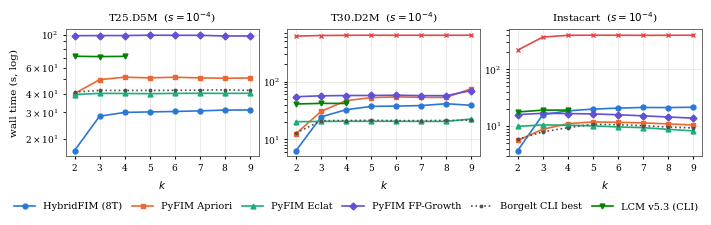

In [8]:
# ------------------------------------------------------ runtime vs k ------
big3 = ["T25.I8.D5000k.N40k.L40k", "T30.I8.D2000k.N10k.L10k", "Instacart"]
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.1), sharey=False)
for ax, d in zip(axes, big3):
    sub = W.loc[d]
    for m in ["fastapriori_fast", "fastapriori_classic", "pyfim_apriori",
              "pyfim_eclat", "pyfim_fpgrowth"]:
        if m in sub and sub[m].notna().any():
            lab, col, ls, mk = STYLE[m]
            s = sub[m].dropna()
            ax.plot(s.index, s.values, color=col, ls=ls, marker=mk, label=lab)
    bb = sub[[c for c in EXTERNAL if c.startswith("borgelt")]].min(axis=1).dropna()
    lab, col, ls, mk = STYLE["borgelt_best"]
    ax.plot(bb.index, bb.values, color=col, ls=ls, marker=mk, label=lab)
    lsub = lcm[(lcm.dataset == d) & lcm.k.isin([2, 3, 4])].sort_values("k")
    if len(lsub):
        lab, col, ls, mk = STYLE["lcm_native"]
        ax.plot(lsub.k, lsub.wall_s, color=col, ls=ls, marker=mk, label=lab)
    ax.set_yscale("log")
    ax.set_title(f"{short(d)}  ($s=10^{{-4}}$)")
    ax.set_xlabel("$k$")
    ax.set_xticks(range(2, 10))
    ax.tick_params(length=2)
axes[0].set_ylabel("wall time (s, log)")
h_, l2 = axes[0].get_legend_handles_labels()
fig.legend(h_, l2, loc="lower center", ncol=7, frameon=False,
           bbox_to_anchor=(0.5, -0.02), handlelength=2.2, columnspacing=1.0)
fig.tight_layout(pad=0.4, rect=(0, 0.1, 1, 1))
fig.savefig(FIG / "runtime_vs_k.pdf")
plt.show()

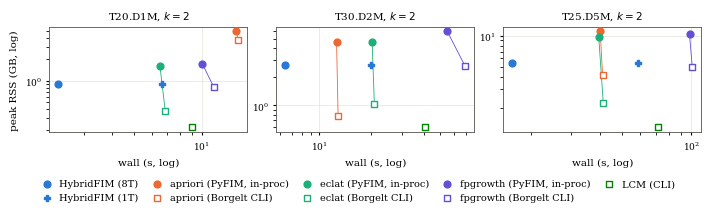

In [9]:
# ------------------------------------------- memory boundary figure -------
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.0))
for ax, d in zip(axes, ["T20.I4.D1000k.N50k.L50k", "T30.I8.D2000k.N10k.L10k",
                        "T25.I8.D5000k.N40k.L40k"]):
    w2, m2 = W.loc[(d, 2)], M.loc[(d, 2)]
    pts = [("fastapriori_fast", "HybridFIM (8T)", C["blue"], True),
           ("fastapriori_fast_1t", "HybridFIM (1T)", C["blue"], "1t")]
    for algo, col in [("apriori", C["orange"]), ("eclat", C["aqua"]), ("fpgrowth", C["violet"])]:
        pts.append((f"pyfim_{algo}", f"{algo} (PyFIM, in-proc)", col, True))
        pts.append((f"borgelt_{algo}", f"{algo} (Borgelt CLI)", col, False))
    for m, lab, col, inproc in pts:
        if m not in w2 or np.isnan(w2[m]):
            continue
        ax.scatter(w2[m], m2[m] / 1024, s=24,
                   marker="P" if inproc == "1t" else ("o" if inproc else "s"),
                   facecolor=col if inproc else "white", edgecolor=col, lw=1.0,
                   label=lab, zorder=3)
    for algo, col in [("apriori", C["orange"]), ("eclat", C["aqua"]), ("fpgrowth", C["violet"])]:
        a, b = f"pyfim_{algo}", f"borgelt_{algo}"
        ax.plot([w2[a], w2[b]], [m2[a] / 1024, m2[b] / 1024], color=col, lw=0.6, zorder=2)
        note(f"RSS pyfim/borgelt {algo} {short(d)}", round(m2[a] / m2[b], 2))
    lr = lcm[(lcm.dataset == d) & (lcm.k == 2)]
    if len(lr):
        ax.scatter(lr.wall_s, lr.peak_rss_mb / 1024, s=24, marker="s", facecolor="white",
                   edgecolor=C["green"], lw=1.0, label="LCM (CLI)", zorder=3)
    note(f"RSS HybridFIM/pyfim_eclat {short(d)}",
         round(m2['fastapriori_fast'] / m2['pyfim_eclat'], 2))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{short(d)}, $k=2$")
    ax.set_xlabel("wall (s, log)")
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.tick_params(length=2)
axes[0].set_ylabel("peak RSS (GB, log)")
h_, l2 = axes[0].get_legend_handles_labels()
fig.legend(h_, l2, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.03),
           columnspacing=0.9, handletextpad=0.3)
fig.tight_layout(pad=0.4, rect=(0, 0.17, 1, 1))
fig.savefig(FIG / "memory_boundary.pdf")
plt.show()

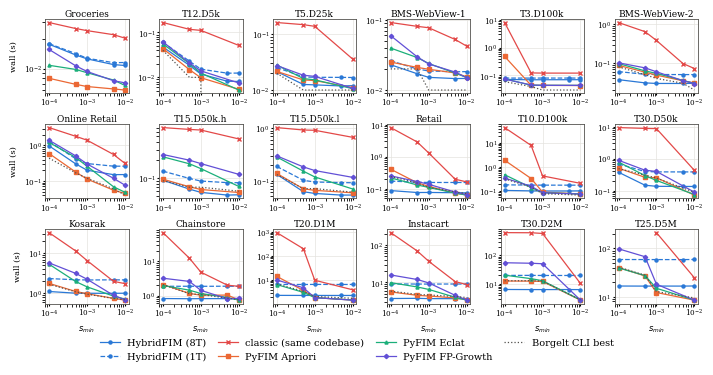

valid_configurations = 4891
spearman(rho, borgeltApriori/1T), all 18 = 0.734
spearman(rho, borgeltApriori/1T), cells >=0.1s = 0.829
spearman(predicted isect ratio, classic/1T) = 0.949
measured/predicted classic ratio: median, min, max = (np.float64(0.079), np.float64(0.009), np.float64(0.166))
rho>=0.9: 1T beats Borgelt Apriori = 5/5
rho<=0.3: Borgelt Apriori beats 1T = 10/10
perlevel k==2 = {'k': '=2', 'pyfim': (np.float64(0.8333333333333334), np.float64(1.4197167923107514), 18), 'ext': (np.float64(0.5555555555555556), np.float64(1.3981720405229425), 18), 'eclat': (np.float64(0.8333333333333334), np.float64(2.385917263730277), 18), 'classic': (np.float64(1.0), np.float64(29.41447101448825), 17), 'real_wins': '5/8', 'syn_wins': '5/10', 'eclat_share': np.float64(0.2222222222222222)}
perlevel k==3 = {'k': '=3', 'pyfim': (np.float64(0.2), np.float64(0.36359678104610754), 15), 'ext': (np.float64(0.2), np.float64(0.36359678104610754), 15), 'eclat': (np.float64(0.2), np.float64(0.36359678104

In [10]:
# ------------------------------------------ k=2 per-variant small multiples
order = list(stats.sort_values("n_rows").index)
fig, axes = plt.subplots(3, 6, figsize=(7.0, 3.6))
for ax, d in zip(axes.ravel(), order):
    try:
        sub = wall_all.xs((d, 2), level=("dataset", "k")).sort_index()
    except KeyError:
        ax.set_visible(False)
        continue
    for m in ["fastapriori_fast", "fastapriori_fast_1t", "fastapriori_classic",
              "pyfim_apriori", "pyfim_eclat", "pyfim_fpgrowth"]:
        if m in sub and sub[m].notna().any():
            lab, col, ls, mk = STYLE[m]
            s = sub[m].dropna()
            ax.plot(s.index, s.values, color=col, ls=ls, marker=mk, ms=2.2, lw=0.9, label=lab)
    bb = sub[["borgelt_apriori", "borgelt_eclat", "borgelt_fpgrowth"]].min(axis=1).dropna()
    lab, col, ls, mk = STYLE["borgelt_best"]
    ax.plot(bb.index, bb.values, color=col, ls=ls, lw=0.9, label=lab)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(short(d), fontsize=6.5, pad=2)
    ax.tick_params(length=1.5, labelsize=5.2, pad=1)
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
for ax in axes[-1]:
    ax.set_xlabel("$s_{min}$", fontsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel("wall (s)", fontsize=6)
h_, l2 = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l2, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01),
           columnspacing=1.2)
fig.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.3, rect=(0, 0.08, 1, 1))
fig.savefig(FIG / "k2_per_variant.pdf")
plt.show()

(GEN / "numbers.txt").write_text("\n".join(numbers) + "\n", encoding="utf-8")
print("\n".join(numbers))

In [11]:
# ------------------------------------- marginal per-level cost (k=2 -> 3) ----
# Each (method, k) cell is an independent process that mines levels 2..k, so
# T(k) - T(k-1) estimates the marginal cost of level k.
lines = []
inc_rows = []
for d in W.index.get_level_values("dataset").unique():
    sub = W.loc[d]
    if 3 not in sub.index or 2 not in sub.index:
        continue
    f2, f3 = sub.loc[2, "fastapriori_fast"], sub.loc[3, "fastapriori_fast"]
    e2s = sub.loc[2, ECLAT]; e3s = sub.loc[3, ECLAT]
    best_e = (e3s).idxmin()
    e2, e3 = e2s[best_e], e3s[best_e]
    if np.isnan(f3) or np.isnan(e3):
        continue
    df_, de_ = f3 - f2, e3 - e2
    inc_rows.append(dict(d=d, f2=f2, e2=e2, dfa=df_, dec=de_, win3=f3 < sub.loc[3, EXTERNAL].min()))
    if max(f3, e3) < 0.5:
        continue
    ratio = "---" if de_ <= 0.01 else f"{df_/de_:.0f}$\\times$"
    lines.append(f"{short(d)} & {f2:.2f} & {e2:.2f} & {e2/f2:.1f}$\\times$ & {df_:.2f} & "
                 f"{max(de_,0):.2f} & {ratio} & {'yes' if f3 < sub.loc[3, EXTERNAL].min() else 'no'} \\\\")
(GEN / "tab_increment_rows.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
inc = pd.DataFrame(inc_rows)
big = inc[(inc.f2 + inc.dfa) > 0.5]
note("level-3 marginal: HybridFIM increment > Eclat increment on",
     f"{(big.dfa > big.dec).sum()}/{len(big)} datasets with T>=0.5s")
(GEN / "numbers.txt").write_text("\n".join(numbers) + "\n", encoding="utf-8")
print(inc.round(3).to_string())

                           d      f2      e2     dfa    dec   win3
0              BMS-WebView-2   0.037   0.097   0.379  0.046  False
1                 Chainstore   0.831   1.988   1.222 -0.136  False
2                  Groceries   0.018   0.010   0.475  0.030  False
3                  Instacart   3.702   9.855  12.075  0.610  False
4           Retail (Belgian)   0.087   0.218   0.588  0.027  False
5     T10.I4.D100k.N25k.L25k   0.109   0.490   0.084  0.031   True
6         T12.I4.D5k.N1k.L1k   0.047   0.050   4.451  0.260  False
7   T15.I8.D50k.N1k.L1k.high   0.092   0.260   5.911  0.530  False
8    T15.I8.D50k.N1k.L1k.low   0.131   0.283   1.864  0.155  False
9    T20.I4.D1000k.N50k.L50k   2.315   6.514   1.629  0.135   True
10   T25.I8.D5000k.N40k.L40k  16.608  39.534  11.648  0.696   True
11     T3.I2.D100k.N50k.L50k   0.072   0.070   0.015 -0.020  False
12   T30.I8.D2000k.N10k.L10k   6.414  20.225  18.104  0.243  False
13       T30.I8.D50k.N5k.L5k   0.379   0.788   3.291  0.055  F

In [12]:
# ---------------------------------------------------- merged dataset table --
QUEST = {  # Quest parameters (T, I, L, corr) for the synthetic grid
    "T3.I2.D100k.N50k.L50k": (3, 2, "50K", 0.25), "T5.I2.D25k.N1k.L1k": (5, 2, "1K", 0.5),
    "T10.I4.D100k.N25k.L25k": (10, 4, "25K", 0.5), "T12.I4.D5k.N1k.L1k": (12, 4, "1K", 0.5),
    "T15.I8.D50k.N1k.L1k.high": (15, 8, "1K", 0.9), "T15.I8.D50k.N1k.L1k.low": (15, 8, "1K", 0.1),
    "T20.I4.D1000k.N50k.L50k": (20, 4, "50K", 0.5), "T25.I8.D5000k.N40k.L40k": (25, 8, "40K", 0.5),
    "T30.I8.D2000k.N10k.L10k": (30, 8, "10K", 0.5), "T30.I8.D50k.N5k.L5k": (30, 8, "5K", 0.5),
}
DOMAIN = {"Groceries": "grocery", "BMS-WebView-1": "clickstream", "BMS-WebView-2": "clickstream",
          "Retail (Belgian)": "retail", "Online Retail": "e-commerce", "Kosarak": "clickstream",
          "Chainstore": "retail", "Instacart": "grocery"}
lines = []
for grp in ("real", "syn"):
    sel = [d for d in stats.sort_values("n_rows").index if (d in REAL) == (grp == "real")]
    for d in sel:
        r = stats.loc[d]
        def ci(v):
            return f"{int(v):,}".replace(",", "{,}")
        f1 = ci(r.F1) + ("" if r.F1_exact else "$^{\\le}$")
        q = QUEST.get(d)
        desc = DOMAIN[d] if q is None else f"$I$={q[1]}, $L$={q[2]}, corr={q[3]}"
        lines.append(f"{short(d)} & {desc} & {fmt_int(r.n_transactions)} & {ci(r.n_items)} & "
                     f"{f1} & {r.avg_items_per_txn:.1f} & {ci(r.max_items_per_txn)} & "
                     f"{r.cv:.2f} & {fmt_int(r.n_rows)} \\\\")
    if grp == "real":
        lines.append("\\midrule")
(GEN / "tab_datasets_rows.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

1695

## B · Figures and tables, part B
The three numerical assertions (4,891 configurations, three repetitions,
Spearman 0.946078) describe the v0.1.0.post1 campaign; they are checked only when `CAMPAIGN` is that campaign.

In [13]:
GEN = DERIVED / "part_b" / "tables"; FIG = DERIVED / "part_b" / "figures"
GEN.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
RIG, CS = AGG_CSV, COST_CSV
short = dict(SHORT)            # SHORT is defined in part A
def name(d): return short.get(d, d)
def num(v, digits=2):
    return '---' if pd.isna(v) else f'{v:.{digits}f}'
def integer(v): return f'{int(v):,}'.replace(',', '{,}')
def rows(file, lines): (GEN / file).write_text('\n'.join(lines) + '\n', encoding='utf-8')

In [14]:
raw = pd.read_csv(RIG)
ok = raw[raw.wall_s_n_ok > 0].copy()
if CAMPAIGN == V010: assert len(ok) == 4891 and ok.dataset.nunique() == 18
if CAMPAIGN == V010: assert (ok.wall_s_n_ok == 3).all()
ext = ['borgelt_apriori', 'borgelt_eclat', 'borgelt_fpgrowth',
       'pyfim_apriori', 'pyfim_eclat', 'pyfim_fpgrowth']
lo = ok[np.isclose(ok.min_support, 1e-4)]
w = lo.pivot_table(index=['dataset', 'k'], columns='method', values='wall_s_median')
stats = pd.read_csv(CS)
st = stats[np.isclose(stats.min_support, 1e-4)].set_index('dataset')
pair = w.xs(2, level='k')
cx = st.join(pair[['fastapriori_classic', 'fastapriori_fast_1t', 'borgelt_apriori']])
cx['observed'] = cx.fastapriori_classic / cx.fastapriori_fast_1t
cx['borgelt_ratio'] = cx.borgelt_apriori / cx.fastapriori_fast_1t
sp = cx[['P1_raw', 'observed']].dropna().corr('spearman').iloc[0, 1]
if CAMPAIGN == V010: assert abs(sp - .946078431372549) < 1e-12
cx.to_csv(GEN / 'pair_model_audit.csv')
rows('tab_datasets_rows.tex', [
    f'{name(d)} & {integer(r.D)} & {integer(r.N)} & {integer(r.F1)} & {r.d_avg:.2f} & {integer(r.d_max)} & {r.d_cv:.2f} & {integer(r.rows)} \\\\'
    for d, r in st.iterrows()])
rows('tab_crossover_rows.tex', [
    f'{name(d)} & {integer(r.F1)} & {r.rho_raw:.3g} & {r.P1_raw:.1f} & {num(r.observed)} & {num(r.borgelt_ratio)} \\\\'
    for d, r in cx.sort_values('rho_raw').iterrows()])

In [15]:
out = []
for k in range(2, 10):
    q = w.xs(k, level='k')
    y = pd.DataFrame({'fast': q.fastapriori_fast, 'external': q[ext].min(axis=1) }).dropna()
    ratio = y.external / y.fast
    out.append(f'{k} & {len(y)} & {int((ratio>1).sum())}/{len(y)} & {ratio.median():.2f} & {num((y.external-y.fast).median())} \\\\')
rows('tab_perlevel_rows.tex', out)

In [16]:
out = []
for d in ['T10.I4.D100k.N25k.L25k', 'T20.I4.D1000k.N50k.L50k', 'T25.I8.D5000k.N40k.L40k',
          'T30.I8.D2000k.N10k.L10k', 'Instacart', 'Chainstore']:
    a, b = w.loc[(d, 2)], w.loc[(d, 3)]
    # Select one Eclat implementation by its k=3 time, then use that same method at k=2.
    em = b[['pyfim_eclat', 'borgelt_eclat']].idxmin()
    out.append(f'{name(d)} & {num(a.fastapriori_fast)} & {num(b.fastapriori_fast)} & {num(a[em])} & {num(b[em])} & {num(b.fastapriori_fast-a.fastapriori_fast)} & {num(b[em]-a[em])} \\\\')
rows('tab_increment_rows.tex', out)

In [17]:
# Counts are deliberately method-specific: auditing equality of outputs is a separate task.
counts = ok[(ok.method == 'fastapriori_fast') & (ok.k.isin([2,3]))]
out = []
for support in sorted(counts.min_support.unique()):
    line = [f'${support:g}$']
    for k in [2,3]:
        q = counts[(counts.k == k) & np.isclose(counts.min_support, support)]
        line += [str(len(q)), integer(q.n_itemsets_median.median()), integer(q.n_itemsets_median.max())]
    out.append(' & '.join(line) + ' \\\\')
rows('tab_output_counts_rows.tex', out)

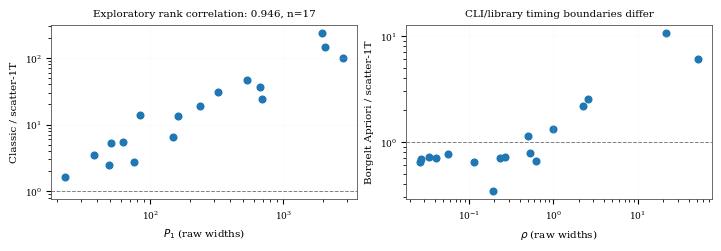

In [18]:
plt.rcParams.update({'font.size':8, 'font.family':'serif', 'pdf.fonttype':42})
fig, axes = plt.subplots(1,2,figsize=(7.1,2.4), layout='constrained')
for ax, x, y, label in [(axes[0],'P1_raw','observed','Classic / scatter-1T'),
                         (axes[1],'rho_raw','borgelt_ratio','Borgelt Apriori / scatter-1T')]:
    q=cx[[x,y]].dropna(); q=q[(q[x]>0)&(q[y]>0)]
    ax.scatter(q[x],q[y],s=23)
    ax.set(xscale='log', yscale='log', xlabel='$P_1$ (raw widths)' if x=='P1_raw' else r'$\rho$ (raw widths)', ylabel=label)
    ax.axhline(1, color='.5', linestyle='--', lw=.7); ax.grid(alpha=.2)
axes[0].set_title(f'Exploratory rank correlation: {sp:.3f}, n=17')
axes[1].set_title('CLI/library timing boundaries differ')
fig.savefig(FIG/'crossover_exact.pdf'); plt.show()

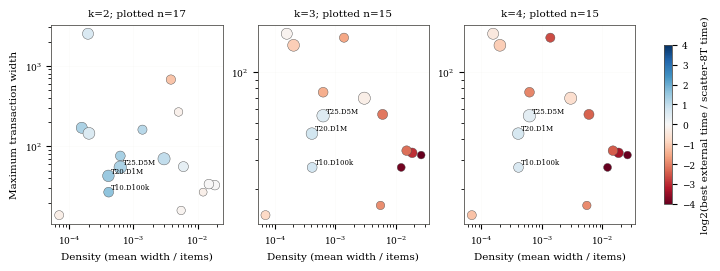

In [19]:
fig, axes=plt.subplots(1,3,figsize=(7.1,2.6),layout='constrained')
for ax,k in zip(axes,[2,3,4]):
    q=w.xs(k,level='k'); ratio=q[ext].min(axis=1)/q.fastapriori_fast
    z=st.join(ratio.rename('ratio')).dropna(subset=['ratio'])
    z=z[z.ratio>0]
    points=ax.scatter(z.d_avg/z.N,z.d_max,c=np.log2(z.ratio),cmap='RdBu',vmin=-4,vmax=4,
                     s=20+15*np.log10(z.rows/1e4+1),edgecolor='.3',linewidth=.3)
    ax.set(xscale='log',yscale='log',title=f'k={k}; plotted n={len(z)}',xlabel='Density (mean width / items)')
    ax.grid(alpha=.15)
    for d in ['T10.I4.D100k.N25k.L25k','T20.I4.D1000k.N50k.L50k','T25.I8.D5000k.N40k.L40k']:
        if d in z.index:
            r=z.loc[d]; ax.annotate(name(d),(r.d_avg/r.N,r.d_max),fontsize=5,xytext=(2,2),textcoords='offset points')
axes[0].set_ylabel('Maximum transaction width')
fig.colorbar(points,ax=axes,label='log2(best external time / scatter-8T time)',shrink=.8)
fig.savefig(FIG/'regime_per_k.pdf'); plt.show()

In [20]:
audit={'source_sha256':{rel(p): sha256(p) for p in [RIG, CS]},
       'completed_configurations':len(ok),'measured_repetitions':int(ok.wall_s_n_ok.sum()),
       'spearman_p1':float(sp),'correlation_n':int(cx.observed.notna().sum()),
       'note':'Dataset statistics recomputed with the current loader, joined to the v0.1.0.post1 timings.'}
(GEN/'audit.json').write_text(json.dumps(audit,indent=2)+'\n',encoding='utf-8')
print(json.dumps(audit,indent=2))

{
  "source_sha256": {
    "results/campaign_2026-05/results_rigorous_20260523_115442.csv": "0f76d3232341a0b8d3670e752da58dc10efa9bbdd0c50f5972fdcf048720a03e",
    "results/campaign_2026-05/cost_stats_20261022.csv": "5aa8c28db2814c67a07cd9c81a81007b93f055115a340d83c24414386e21fa9e"
  },
  "completed_configurations": 4891,
  "measured_repetitions": 14673,
  "spearman_p1": 0.946078431372549,
  "correlation_n": 17,
  "note": "Dataset statistics recomputed with the current loader, joined to the v0.1.0.post1 timings."
}


## C · Big-data and ablation tables

**Big-data table** (`tab:bigdata`). Source: aggregated `wall_s_median` / `peak_rss_kb_median` at
support 1e-4; the k≥3 column is the median over k=3…9; LCM from its own CSV (k=3,4 only). RSS is
converted from KiB (`/usr/bin/time`) to GiB = KiB/1024². Bold marks the fastest time and the smallest
RSS per column.

**Ablation table** (`tab:ablation`). A1–A3 from `ablation_results.csv` (v0/v1, v1/v2, v2/v3 median
wall ratios; Kosarak at 1e-3, others 1e-4); A4 (−Parallel) = fast_1t / fast at k=2 from the
aggregated table. N and d_max come from the dataset statistics.

In [21]:
agg = pd.read_csv(AGG_CSV, low_memory=False)
ok = agg[agg.wall_s_n_ok > 0]
lo4 = ok[np.isclose(ok.min_support, 1e-4)]
lcm = pd.read_csv(LCM_CSV)
BIG = [("T20.I4.D1000k.N50k.L50k", "T20.D1M (20\\,M rows)"),
       ("T30.I8.D2000k.N10k.L10k", "T30.D2M (60\\,M rows)"),
       ("T25.I8.D5000k.N40k.L40k", "T25.D5M (125\\,M rows)")]
METHODS = [("fastapriori_fast", "\\fast{} (8T)"), ("fastapriori_fast_1t", "\\fastoneT{}"),
           ("fastapriori_classic", "\\classic{}"), ("pyfim_apriori", "\\pyfim{} Apriori"),
           ("pyfim_eclat", "\\pyfim{} Eclat"), ("pyfim_fpgrowth", "\\pyfim{} FP-Growth"),
           ("borgelt_apriori", "\\borgelt{} Apriori"), ("borgelt_eclat", "\\borgelt{} Eclat"),
           ("borgelt_fpgrowth", "\\borgelt{} FP-Growth"),
           ("lcm", "\\lcm{} v5.3" + ("" if CAMPAIGN == V010 else " (v0.1.0.post1)"))]
KIB_PER_GIB = 1024 ** 2

def cell_value(ds, m, higher):
    """(seconds, GiB) for k=2 or the median over k>=3 (lcm: k=3,4 from its own CSV)."""
    if m == "lcm":
        q = lcm[(lcm.dataset == ds) & (lcm.status == "ok") if "status" in lcm else (lcm.dataset == ds)]
        q = q[q.k >= 3] if higher else q[q.k == 2]
        if q.empty: return (np.nan, np.nan)
        return (q.wall_s.median(), q.peak_rss_mb.median() / 1024)
    q = lo4[(lo4.dataset == ds) & (lo4.method == m)]
    q = q[q.k >= 3] if higher else q[q.k == 2]
    if q.empty: return (np.nan, np.nan)
    return (q.wall_s_median.median(), q.peak_rss_kb_median.median() / KIB_PER_GIB)

vals = {(m, ds, h): cell_value(ds, m, h) for m, _ in METHODS for ds, _ in BIG for h in (False, True)}
bigdata = pd.DataFrame({f"{ds} {'k>=3' if h else 'k=2'}": {lab: vals[(m, ds, h)] for m, lab in METHODS}
                        for ds, _ in BIG for h in (False, True)})
bigdata

,T20.I4.D1000k.N50k.L50k k=2,T20.I4.D1000k.N50k.L50k k>=3,T30.I8.D2000k.N10k.L10k k=2,T30.I8.D2000k.N10k.L10k k>=3,T25.I8.D5000k.N40k.L40k k=2,T25.I8.D5000k.N40k.L40k k>=3
\fast{} (8T),"(2.314592365000862, 0.9116172790527344)","(4.52239242900032, 0.9115447998046875)","(6.413885387999471, 2.661407470703125)","(37.71225997299916, 6.026958465576172)","(16.60769243999675, 5.444770812988281)","(30.4109021760014, 5.4448089599609375)"
\fastoneT{},"(6.623688570998638, 0.9117012023925781)","(nan, nan)","(19.83987982799954, 2.661388397216797)","(nan, nan)","(58.91919964100089, 5.444877624511719)","(nan, nan)"
\classic{},"(955.433462072, 50.769309997558594)","(958.6439327659972, 50.610050201416016)","(613.3937627659998, 5.744876861572266)","(633.4931306400031, 5.615512847900391)","(nan, nan)","(nan, nan)"
\pyfim{} Apriori,"(14.2369884380023, 4.9341278076171875)","(17.23026623000624, 5.058929443359375)","(12.63406565600053, 4.668422698974609)","(53.25339604500914, 4.668712615966797)","(40.14291203600078, 10.97580337524414)","(51.15154952200828, 11.23885726928711)"
\pyfim{} Eclat,"(6.514408901999559, 1.6345977783203125)","(6.76195189000282, 1.634735107421875)","(20.22496785600015, 4.668704986572266)","(20.55137235099392, 4.668712615966797)","(39.53408584999852, 9.743728637695312)","(40.23009694199573, 9.743865966796875)"
\pyfim{} FP-Growth,"(10.0501881880009, 1.727203369140625)","(10.14103031498962, 1.7227706909179688)","(54.750087041999, 5.961460113525391)","(57.42007734900108, 5.92095947265625)","(98.29591075900316, 10.312553405761719)","(98.49762221499986, 10.303752899169922)"
\borgelt{} Apriori,"(14.52, 3.7684669494628906)","(17.63, 3.8936729431152344)","(12.89, 0.7716140747070312)","(53.29, 1.0762786865234375)","(41.09, 4.136692047119141)","(52.66, 4.406002044677734)"
\borgelt{} Eclat,"(6.88, 0.3786811828613281)","(7.07, 0.378662109375)","(20.83, 1.0459251403808594)","(21.2, 1.0459480285644531)","(41.37, 2.220653533935547)","(42.18, 2.2205810546875)"
\borgelt{} FP-Growth,"(11.31, 0.8084259033203125)","(11.32, 0.8083114624023438)","(69.49, 2.558979034423828)","(69.42, 2.5589942932128906)","(101.01, 5.001220703125)","(101.4, 5.001125335693359)"
\lcm{} v5.3,"(9.010617405, 0.2223968505859375)","(9.044505473, 0.22241592412109376)","(40.95737603, 0.59098434453125)","(41.938992715, 0.59098434453125)","(71.45185792, 1.287845611328125)","(71.24367152, 1.2878150942382813)"


In [22]:
def fmt_t(t):  return f"{t:.0f}" if t >= 500 else f"{t:.1f}"
def fmt_g(g):  return f"{g:.2f}" if g < 1 else f"{g:.1f}"
cols = [(ds, h) for ds, _ in BIG for h in (False, True)]
best_t = {c: np.nanmin([vals[(m, c[0], c[1])][0] for m, _ in METHODS]) for c in cols}
best_g = {c: np.nanmin([vals[(m, c[0], c[1])][1] for m, _ in METHODS]) for c in cols}
body = []
for m, lab in METHODS:
    cells = []
    for c in cols:
        t, g = vals[(m, c[0], c[1])]
        if np.isnan(t):
            cells.append("---"); continue
        ts, gs = fmt_t(t), fmt_g(g)
        if np.isclose(t, best_t[c]): ts = f"\\textbf{{{ts}}}"
        if np.isclose(g, best_g[c]): gs = f"\\textbf{{{gs}}}"
        cells.append(f"{ts} / {gs}")
    body.append(f"{lab:<24}& " + " & ".join(cells) + "\\\\")

bigdata_tex = r"""\begin{table*}[t]
\caption{Large workloads at $s=10^{-4}$: median runtime (s) / peak RSS (GiB). The $k\ge3$ column is the median across k=3\ldots9 (LCM: k=3,4); Table~\ref{tab:perlevel} and Figure~\ref{fig:vsk} resolve individual levels. In-process RSS includes interpreter/input/conversion allocations; native CLI input/output boundaries differ. LCM is a separate restricted-coverage comparison.}\label{tab:bigdata}
\small\setlength{\tabcolsep}{4pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}lcccccc@{}}
\toprule
& """ + " & ".join(f"\\multicolumn{{2}}{{c}}{{{lab}}}" for _, lab in BIG) + r"""\\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Method & $k=2$ & $k\ge3$ & $k=2$ & $k\ge3$ & $k=2$ & $k\ge3$\\
\midrule
""" + "\n".join(body) + r"""
\bottomrule
\end{tabular*}
\end{table*}
"""
(DERIVED / "part_c").mkdir(parents=True, exist_ok=True)
(DERIVED / "part_c" / "bigdata.tex").write_text(bigdata_tex, encoding="utf-8")
print(bigdata_tex)

\begin{table*}[t]
\caption{Large workloads at $s=10^{-4}$: median runtime (s) / peak RSS (GiB). The $k\ge3$ column is the median across k=3\ldots9 (LCM: k=3,4); Table~\ref{tab:perlevel} and Figure~\ref{fig:vsk} resolve individual levels. In-process RSS includes interpreter/input/conversion allocations; native CLI input/output boundaries differ. LCM is a separate restricted-coverage comparison.}\label{tab:bigdata}
\small\setlength{\tabcolsep}{4pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}lcccccc@{}}
\toprule
& \multicolumn{2}{c}{T20.D1M (20\,M rows)} & \multicolumn{2}{c}{T30.D2M (60\,M rows)} & \multicolumn{2}{c}{T25.D5M (125\,M rows)}\\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Method & $k=2$ & $k\ge3$ & $k=2$ & $k\ge3$ & $k=2$ & $k\ge3$\\
\midrule
\fast{} (8T)            & \textbf{2.3} / 0.91 & \textbf{4.5} / 0.91 & \textbf{6.4} / 2.7 & 37.7 / 6.0 & \textbf{16.6} / 5.4 & \textbf{30.4} / 5.4\\
\fastoneT{}             & 6.6 / 0.91 & --- & 19.8 / 2.7 & --- & 58.9 /

In [23]:
abl = pd.read_csv(V010_DIR / "ablation_results.csv")
abl = abl[abl.status == "ok"]
cs = pd.read_csv(COST_CSV)
ABL_SUPPORT = {"Kosarak": 1e-3}
ABL_ORDER = ["Groceries", "T25.I8.D5000k.N40k.L40k", "Instacart", "BMS-WebView-2", "Kosarak"]
ABL_NAME = {"T25.I8.D5000k.N40k.L40k": "T25.D5M"}

def med(ds, k, variant):
    s = ABL_SUPPORT.get(ds, 1e-4)
    q = abl[(abl.dataset == ds) & (abl.k == k) & np.isclose(abl.min_support, s) & (abl.variant == variant)]
    assert len(q) == 1, (ds, k, variant, len(q))
    return float(q.wall_s_median.iloc[0])

recs = []
for ds in ABL_ORDER:
    s = ABL_SUPPORT.get(ds, 1e-4)
    k2 = lo4 if s == 1e-4 else ok[np.isclose(ok.min_support, s)]
    k2 = k2[(k2.dataset == ds) & (k2.k == 2)].set_index("method").wall_s_median
    st = cs[(cs.dataset == ds)].iloc[0]
    recs.append(dict(dataset=ds, N=int(st.N), d_max=int(st.d_max),
                     A1=med(ds, 3, "v0_baseline") / med(ds, 3, "v1_roaring"),
                     A2a=med(ds, 3, "v1_roaring") / med(ds, 3, "v2_memo"),
                     A2b=med(ds, 4, "v1_roaring") / med(ds, 4, "v2_memo"),
                     A3=med(ds, 3, "v2_memo") / med(ds, 3, "v3_adaptive"),
                     A4=k2.get("fastapriori_fast_1t", np.nan) / k2.get("fastapriori_fast", np.nan)))
ablation = pd.DataFrame(recs).sort_values("d_max")
display(ablation.round(3))

def x(v):
    s = f"{v:.2f}$\\times$"
    return f"\\textbf{{{s}}}" if v >= 2 else s
lines = [f"{ABL_NAME.get(r.dataset, r.dataset):<13} & {r.N:,} & {r.d_max:,} & {x(r.A1)} & {x(r.A2a)} & {x(r.A2b)} & {x(r.A3)} & {x(r.A4)}\\\\"
         .replace(",", "{,}") for r in ablation.itertuples()]
ablation_tex = r"""\begin{table*}[t]
\caption{Ablation: wall-time slowdown when a component is removed
(variant/full; $>1$ means the component helps). $s=10^{-3}$ for Kosarak and
$10^{-4}$ elsewhere. A1, A2a and A3 are at $k\!=\!3$, A2b at $k\!=\!4$, A4 at
$k\!=\!2$ (one/eight-thread \fast{}). Rows are sorted by $\dmax$.}\label{tab:ablation}
\small\setlength{\tabcolsep}{6pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}lrrccccc@{}}
\toprule
Dataset & $N$ & $\dmax$ & A1: $-$Roaring & A2a: $-$Memo ($k$=3) & A2b: $-$Memo ($k$=4) & A3: $-$Adaptive & A4: $-$Parallel\\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular*}
\end{table*}
"""
(DERIVED / "part_c").mkdir(parents=True, exist_ok=True)
(DERIVED / "part_c" / "ablation.tex").write_text(ablation_tex, encoding="utf-8")
print(ablation_tex)

,dataset,N,d_max,A1,A2a,A2b,A3,A4
0,Groceries,169,32,0.882,0.902,0.864,1.029,1.014
1,T25.I8.D5000k.N40k.L40k,39986,55,0.820,1.473,1.479,1.028,3.548
2,Instacart,49677,145,0.609,1.788,2.423,1.035,2.454
3,BMS-WebView-2,3340,161,0.969,1.927,2.793,1.087,1.615
4,Kosarak,41270,2497,0.712,1.525,7.604,1.063,2.145


\begin{table*}[t]
\caption{Ablation: wall-time slowdown when a component is removed
(variant/full; $>1$ means the component helps). $s=10^{-3}$ for Kosarak and
$10^{-4}$ elsewhere. A1, A2a and A3 are at $k\!=\!3$, A2b at $k\!=\!4$, A4 at
$k\!=\!2$ (one/eight-thread \fast{}). Rows are sorted by $\dmax$.}\label{tab:ablation}
\small\setlength{\tabcolsep}{6pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}lrrccccc@{}}
\toprule
Dataset & $N$ & $\dmax$ & A1: $-$Roaring & A2a: $-$Memo ($k$=3) & A2b: $-$Memo ($k$=4) & A3: $-$Adaptive & A4: $-$Parallel\\
\midrule
Groceries     & 169 & 32 & 0.88$\times$ & 0.90$\times$ & 0.86$\times$ & 1.03$\times$ & 1.01$\times$\\
T25.D5M       & 39{,}986 & 55 & 0.82$\times$ & 1.47$\times$ & 1.48$\times$ & 1.03$\times$ & \textbf{3.55$\times$}\\
Instacart     & 49{,}677 & 145 & 0.61$\times$ & 1.79$\times$ & \textbf{2.42$\times$} & 1.04$\times$ & \textbf{2.45$\times$}\\
BMS-WebView-2 & 3{,}340 & 161 & 0.97$\times$ & 1.93$\times$ & \textbf{2.79$\times$} & 1.09